# Quiz
### Guideline
1. Please submit the file via Google Classroom.
2. File name convention is MSA38DN_\<Your full name\>\_quiz03
3. Provide your personal information in the next block.

### Student information
Full name: Bùi Ngọc Bảo Trân

Student ID: 25MS33062

Group: 2

In [1]:
import os
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

import requests

# define your addition imported libraries below

In [2]:
def download_input_data(url):
  print(f"Downloading from {url}")
  # Download the image.
  response = requests.get(url, stream=True)
  response.raise_for_status()

  # Read the image data from the response
  image_data = np.asarray(bytearray(response.content), dtype="uint8")

  # Decode the image using OpenCV
  img_gray = cv.imdecode(image_data, cv.IMREAD_GRAYSCALE)

  return img_gray

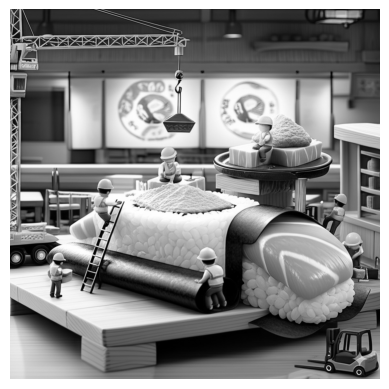

In [3]:
file_id = '1WRLpWrhsJgguvdAdFNcdGZdc_3NrTmjq'
download_url = f'https://drive.google.com/uc?export=download&id={file_id}'
img_gray = download_input_data(download_url)

plt.imshow(img_gray, cmap='gray')
plt.axis('off')
plt.show()

# Questions
1. Convert the input image from 256 grayscale levels to 32 ones.
2. Create a new image from the input image, in which each one fourth part has a different grayscale level.
3. Create a new image from the input image, in which each one third part is applied a different filter effect. Briefly introduce those effects.
4. Introduce and applied the "twirl" effect to the input image. Note, you can find more information about this effect in several sources, including the textbook.
5. Redo (4) with your own grayscale image.

Note, plot the output image(s) for every question.



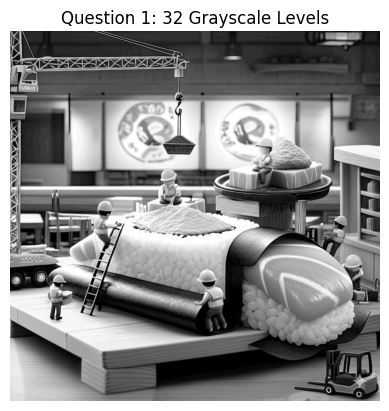

In [12]:
# 1. Convert the input image from 256 grayscale levels to 32 ones.

img_32 = (img_gray // 8) * 8

# Display result
plt.imshow(img_32, cmap='gray')
plt.title("Question 1: 32 Grayscale Levels")
plt.axis('off')
plt.show()

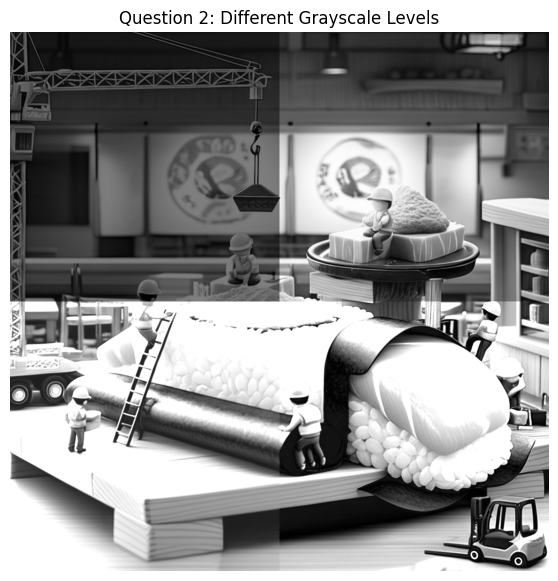

In [13]:
# 2. Create a new image from the input image, in which each one fourth part has a different grayscale level.

h, w = img_gray.shape

img_q2 = np.zeros_like(img_gray)

# Divide image into 4 different zones
half_h = h // 2
half_w = w // 2

# Zone 1: Darker
img_q2[:half_h, :half_w] = cv.convertScaleAbs(
    img_gray[:half_h, :half_w],
    alpha=0.5,
    beta=0
)

# Zone 2: Original
img_q2[:half_h, half_w:] = img_gray[:half_h, half_w:]

# Zone 3: Brighter
img_q2[half_h:, :half_w] = cv.convertScaleAbs(
    img_gray[half_h:, :half_w],
    alpha=1.3,
    beta=30
)

# Zone 4: High Contrast
img_q2[half_h:, half_w:] = cv.convertScaleAbs(
    img_gray[half_h:, half_w:],
    alpha=1.8,
    beta=-20
)

# Display result
plt.figure(figsize=(7,7))
plt.imshow(img_q2, cmap='gray')
plt.title("Question 2: Different Grayscale Levels")
plt.axis('off')
plt.show()

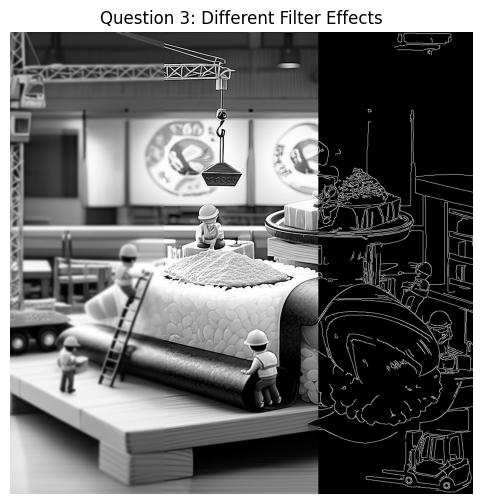

1. Gaussian Blur:
- Smooths the image by averaging nearby pixels.
- Reduces noise and small details.
- Commonly used before edge detection or image preprocessing.

2. Sharpen Filter:
- Enhances edges and fine details in the image.
- Makes the image appear clearer and more focused.
- Useful for highlighting textures and object boundaries.

3. Edge Detection:
- Detects strong intensity changes in the image.
- Extracts object boundaries and important contours.
- Commonly used in object detection and computer vision tasks.


In [14]:
# 3. Create a new image from the input image, in which each one third part is applied a different filter effect. Briefly introduce those effects.

# Divide image vertically into 3 different zones
third = w // 3

# Create output image
img_q3 = np.zeros_like(img_gray)

# Zone 1: Gaussian Blur
blur_part = cv.GaussianBlur(
    img_gray[:, :third],
    (11,11),
    0
)

img_q3[:, :third] = blur_part

# Zone 2: Sharpen Filter
kernel_sharpen = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

sharp_part = cv.filter2D(
    img_gray[:, third:2*third],
    -1,
    kernel_sharpen
)

img_q3[:, third:2*third] = sharp_part

# Zone 3: Edge Detection
edge_part = cv.Canny(
    img_gray[:, 2*third:],
    100,
    200
)

img_q3[:, 2*third:] = edge_part

# Display result
plt.figure(figsize=(12,6))
plt.imshow(img_q3, cmap='gray')
plt.title("Question 3: Different Filter Effects")
plt.axis('off')
plt.show()

# Brief introduction of effects
print("1. Gaussian Blur:")
print("- Smooths the image by averaging nearby pixels.")
print("- Reduces noise and small details.")
print("- Commonly used before edge detection or image preprocessing.\n")

print("2. Sharpen Filter:")
print("- Enhances edges and fine details in the image.")
print("- Makes the image appear clearer and more focused.")
print("- Useful for highlighting textures and object boundaries.\n")

print("3. Edge Detection:")
print("- Detects strong intensity changes in the image.")
print("- Extracts object boundaries and important contours.")
print("- Commonly used in object detection and computer vision tasks.")

Twirl Effect:
The twirl effect rotates pixels around the image center.
Pixels near the center are rotated more strongly,
creating a spiral-like distortion.


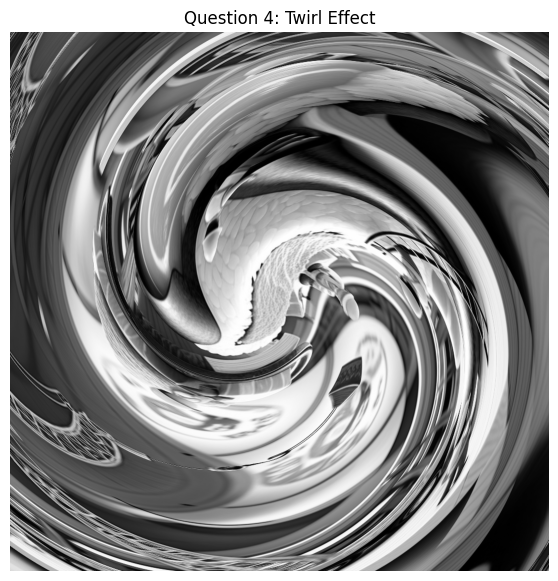

In [15]:
# 4. Introduce and applied the "twirl" effect to the input image. Note, you can find more information about this effect in several sources, including the textbook.

# Twirl Intoduction
print("Twirl Effect:")
print("The twirl effect rotates pixels around the image center.")
print("Pixels near the center are rotated more strongly,")
print("creating a spiral-like distortion.")

from scipy.ndimage import map_coordinates

# Twirl function
def twirl_effect(image, strength=5):

    h, w = image.shape

    center_x = w / 2
    center_y = h / 2

    y, x = np.indices((h, w))

    x_shift = x - center_x
    y_shift = y - center_y

    radius = np.sqrt(x_shift**2 + y_shift**2)
    angle = np.arctan2(y_shift, x_shift)

    max_radius = np.max(radius)

    # Twirl transformation
    twist = strength * (max_radius - radius) / max_radius
    new_angle = angle + twist

    new_x = center_x + radius * np.cos(new_angle)
    new_y = center_y + radius * np.sin(new_angle)

    # Remap image
    twirled = map_coordinates(
        image,
        [new_y.ravel(), new_x.ravel()],
        order=1,
        mode='reflect'
    ).reshape((h, w))

    return twirled.astype(np.uint8)

# Apply twirl effect
img_twirl = twirl_effect(img_gray, strength=5)

# Display result
plt.figure(figsize=(7,7))
plt.imshow(img_twirl, cmap='gray')
plt.title("Question 4: Twirl Effect")
plt.axis('off')
plt.show()

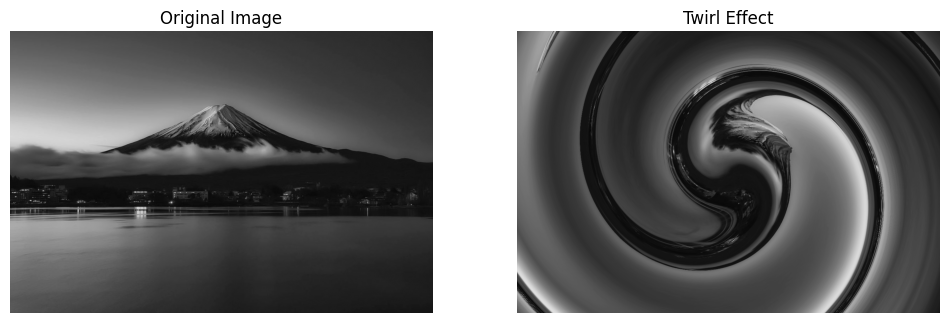

In [16]:
# 5. Redo (4) with your own grayscale image.

download_url = "https://i.pinimg.com/1200x/ab/53/ca/ab53cab7e9784f2f5794f96cee7d5f1d.jpg"

response = requests.get(download_url, stream=True)
response.raise_for_status()

image_data = np.asarray(bytearray(response.content), dtype="uint8")

my_img = cv.imdecode(image_data, cv.IMREAD_GRAYSCALE)

# Apply twirl effect
my_twirl = twirl_effect(my_img, strength=7)

# Display results
plt.figure(figsize=(12,6))

# Original image
plt.subplot(1, 2, 1)
plt.imshow(my_img, cmap='gray')
plt.title("Original Image")
plt.axis('off')

# Twirl result
plt.subplot(1, 2, 2)
plt.imshow(my_twirl, cmap='gray')
plt.title("Twirl Effect")
plt.axis('off')

plt.show()